# Explore the Green Taxi data (Jan–Mar 2025)

Exploration only — the pipeline in `src/green_taxi/` runs without this notebook.

Goal: find the columns needed for **revenue per day** (when the trip happened, what was paid), check their types, missing values and ranges, and decide what to clean.

Run `uv run python -m green_taxi.extract` first to stage the files.

In [1]:
from pathlib import Path
import pandas as pd

RAW = Path('..') / 'data' / 'raw'
files = sorted(RAW.glob('green_tripdata_2025-*.parquet'))
df = pd.concat([pd.read_parquet(f).assign(file=f.name[15:22]) for f in files], ignore_index=True)
df.groupby('file').size()

file
2025-01    48326
2025-02    46621
2025-03    51539
dtype: int64

## Columns and types
`lpep_pickup_datetime` tells us the day; `total_amount` is what the passenger was charged (fare + tips + tolls + taxes + surcharges). Both are already the right dtype.

In [2]:
df.dtypes

VendorID                          int32
lpep_pickup_datetime     datetime64[us]
lpep_dropoff_datetime    datetime64[us]
store_and_fwd_flag                  str
RatecodeID                      float64
PULocationID                      int32
DOLocationID                      int32
passenger_count                 float64
trip_distance                   float64
fare_amount                     float64
extra                           float64
mta_tax                         float64
tip_amount                      float64
tolls_amount                    float64
ehail_fee                       float64
improvement_surcharge           float64
total_amount                    float64
payment_type                    float64
trip_type                       float64
congestion_surcharge            float64
cbd_congestion_fee              float64
file                                str
dtype: object

## Missing values
The two columns we need are never null. About 2–7% of rows miss `payment_type`, `passenger_count` etc., but still have an amount, so they are kept. `ehail_fee` is always empty.

In [3]:
df.isna().sum()[lambda s: s > 0]

store_and_fwd_flag        7902
RatecodeID                7902
passenger_count           7902
ehail_fee               146486
payment_type              7902
trip_type                 7926
congestion_surcharge      7902
cbd_congestion_fee        3824
dtype: int64

## Dates: trips from outside the file's month
Each file contains a few trips from neighbouring months. Trips from other months *inside* Jan–Mar simply go to the right day; trips before 2025-01-01 or from 2025-04-01 are outside the report and are dropped.

In [4]:
pu = df['lpep_pickup_datetime']
print(pu.min(), '->', pu.max())
outside = df[(pu < '2025-01-01') | (pu >= '2025-04-01')]
outside['lpep_pickup_datetime'].dt.date.value_counts().sort_index()

2024-12-25 23:13:15 -> 2025-04-01 23:41:29


lpep_pickup_datetime
2024-12-25    1
2024-12-29    1
2024-12-31    4
2025-04-01    5
Name: count, dtype: int64

## Amounts: ranges, zeros and negatives

In [5]:
amt = df['total_amount']
amt.describe().round(2)

count    146486.00
mean         23.18
std          16.49
min        -473.10
25%          13.80
50%          18.90
75%          27.18
max         642.14
Name: total_amount, dtype: float64

In [6]:
pd.Series({'negative': (amt < 0).sum(), 'zero': (amt == 0).sum(), 'over $1000': (amt > 1000).sum()})

negative      478
zero          254
over $1000      0
dtype: int64

Negative amounts look like **refunds**: almost every one has a positive twin with the same vendor, pickup/dropoff time, locations and the opposite amount. Their payment types are mostly 3 (no charge) and 4 (dispute).

In [7]:
key = ['VendorID', 'lpep_pickup_datetime', 'lpep_dropoff_datetime', 'PULocationID', 'DOLocationID']
neg = df[amt < 0].assign(a=-df['total_amount'])
pos = df[amt > 0].assign(a=df['total_amount'])
m = neg.merge(pos[key + ['a', 'payment_type']], on=key + ['a'], how='left', suffixes=('', '_original'), indicator=True)
print('refunds with a matching original charge:', (m['_merge'] == 'both').sum(), 'of', len(neg))
m['payment_type_original'].value_counts(dropna=False)

refunds with a matching original charge: 468 of 478


payment_type_original
3.0    322
4.0    111
2.0     35
NaN     10
Name: count, dtype: int64

**Decision:** remove each refund *together with* the charge it cancels, so voided trips count neither as revenue nor as trips. The ~10 refunds without an original in the data are kept (they still reduce revenue). `$0` trips add nothing to revenue and are not counted as paid trips.

## Dropoff before pickup
About 500 trips, almost all from vendor 6, with the dropoff at most a few minutes before the pickup — a clock problem, not a fake trip. The amount and pickup date are fine, so they are kept.

In [8]:
bad = df[df['lpep_dropoff_datetime'] < pu]
print(len(bad), 'rows; vendors:', bad['VendorID'].value_counts().to_dict())
((bad['lpep_pickup_datetime'] - bad['lpep_dropoff_datetime']).dt.total_seconds() / 60).describe().round(1)

518 rows; vendors: {6: 517, 1: 1}


count    518.0
mean       0.4
std        0.4
min        0.0
25%        0.2
50%        0.3
75%        0.5
max        7.4
dtype: float64

## Summary of cleaning rules (implemented in `src/green_taxi/transform.py`)

| Issue | Rows | Rule |
|---|---|---|
| Missing pickup time or amount | 0 | drop (kept as a safety check) |
| Pickup outside Jan–Mar 2025 | 11 | drop |
| Refund + the charge it reverses | 936 (468 pairs) | drop both |
| Refund without matching charge | ~10 | keep — reduces revenue |
| `$0` amount | ~250 | keep, not counted as a paid trip |
| Dropoff before pickup | ~500 | keep — clock error, amount is valid |
| Odd `trip_distance` values | 55 > 200 mi | ignore — not used for revenue |

## Quick look at the result the pipeline should produce

90 days, net revenue $3,395,290.56


Matplotlib is building the font cache; this may take a moment.


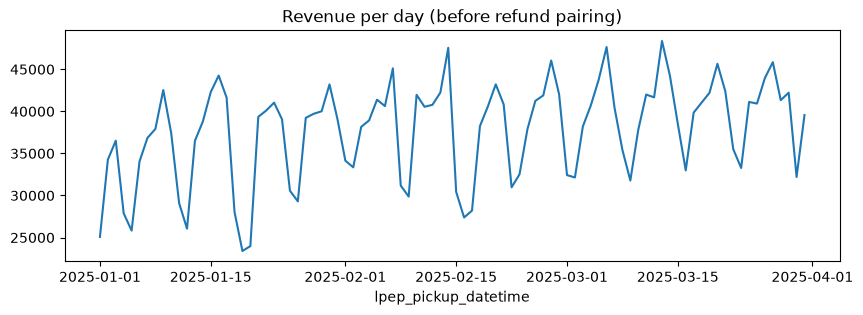

In [9]:
naive = df[(pu >= '2025-01-01') & (pu < '2025-04-01')].groupby(pu.dt.date)['total_amount'].sum()
print(f'{len(naive)} days, net revenue ${naive.sum():,.2f}')
naive.plot(figsize=(10, 3), title='Revenue per day (before refund pairing)');